## **Importing Libraries**

In [56]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error , mean_absolute_error , r2_score

## **Loaded dataset car details from car dekho**

In [57]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,fuel_encoded,transmission_encoded
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,4,1
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,4,1
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,1,1
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,4,1
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,1,1


## **Finding null values and droping**

In [58]:
df = pd.read_csv("/content/CAR DETAILS FROM CAR DEKHO.csv")
print("Before dropping null values:\n")
print(df.isnull().sum())
df.dropna(inplace=True)
print("After dropping null values:\n")
print(df.isnull().sum())

Before dropping null values:

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64
After dropping null values:

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


## **Checking duplicates and droping**

In [59]:
print("number of dublicated",df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("number of duplicated after dropping:", df.duplicated().sum())

number of dublicated 763
number of duplicated after dropping: 0


## **Applying label encoding on Fuel and Transmission columns**

In [60]:
FUEL = LabelEncoder()
df["fuel_encoded"] = FUEL.fit_transform(df["fuel"])
df.head(10)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,fuel_encoded
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,4
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,4
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,1
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,4
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,1
5,Maruti Alto LX BSIII,2007,140000,125000,Petrol,Individual,Manual,First Owner,4
6,Hyundai Xcent 1.2 Kappa S,2016,550000,25000,Petrol,Individual,Manual,First Owner,4
7,Tata Indigo Grand Petrol,2014,240000,60000,Petrol,Individual,Manual,Second Owner,4
8,Hyundai Creta 1.6 VTVT S,2015,850000,25000,Petrol,Individual,Manual,First Owner,4
9,Maruti Celerio Green VXI,2017,365000,78000,CNG,Individual,Manual,First Owner,0


In [61]:
TRAN = LabelEncoder()
df["transmission_encoded"] = TRAN.fit_transform(df["transmission"])
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,fuel_encoded,transmission_encoded
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,4,1
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,4,1
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,1,1
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,4,1
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,1,1


## **Checking outlaiers**

<Axes: xlabel='selling_price'>

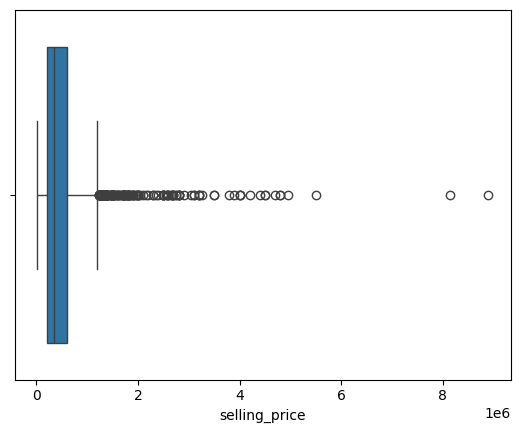

In [62]:
sns.boxplot(x=df["selling_price"])

<Axes: xlabel='km_driven'>

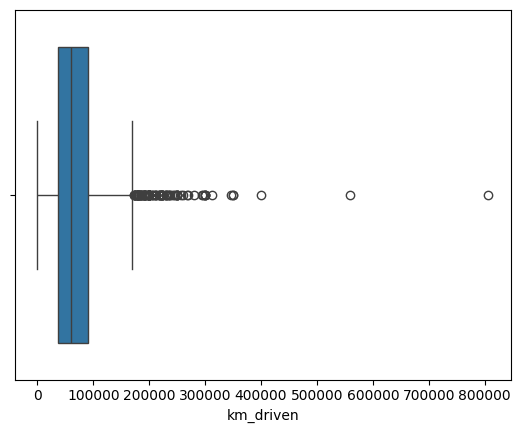

In [63]:
sns.boxplot(x=df["km_driven"])

<Axes: xlabel='year'>

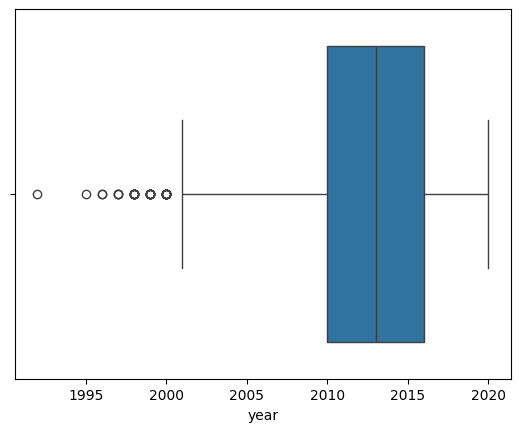

In [64]:
sns.boxplot(x=df["year"])

## **Removing outliers**

In [65]:
Q1 = df["selling_price"].quantile(0.25)
Q3 = df["selling_price"].quantile(0.75)
IQR = Q3 - Q1

df = df[(df["selling_price"] >= Q1 - 1.5*IQR) & (df["selling_price"] <= Q3 + 1.5*IQR)]

<Axes: xlabel='selling_price'>

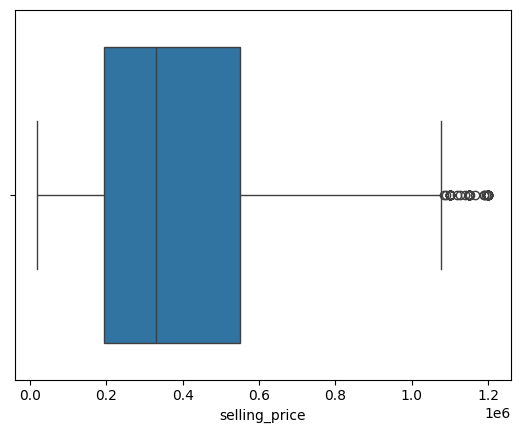

In [66]:
sns.boxplot(x=df["selling_price"])

<Axes: xlabel='km_driven'>

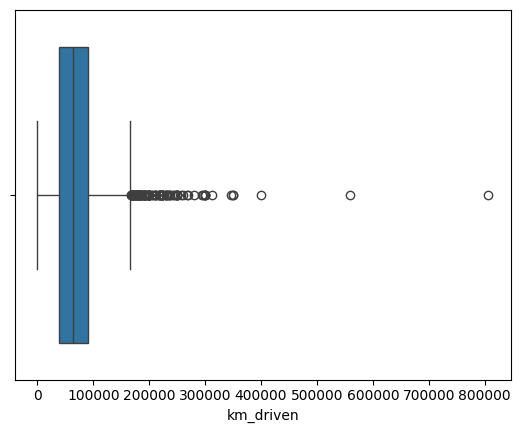

In [67]:
sns.boxplot(x=df["km_driven"])

<Axes: xlabel='year'>

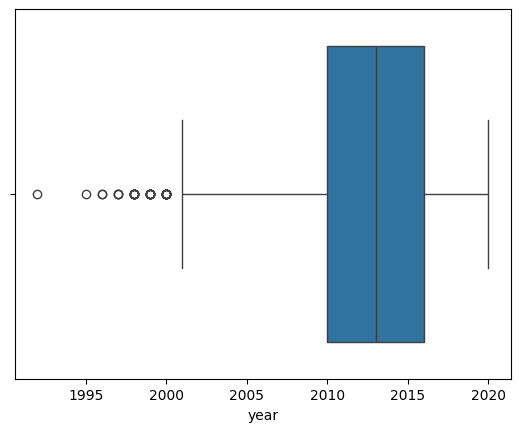

In [68]:
sns.boxplot(x=df["year"])

## **Separating X and Y**

In [69]:
X = df[["year", "km_driven", "fuel_encoded", "transmission_encoded"]]
Y = df["selling_price"]
print("Feature shape:", X.shape, "Target shape:", Y.shape)

Feature shape: (3407, 4) Target shape: (3407,)


## **Splitting Training (80%) Testing (20%)**

In [70]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.20,random_state=42)

In [71]:
print("records for training:",len(X_train))
print("records for testing:",len(X_test))

records for training: 2725
records for testing: 682


## **Applying MinMax scaler on Xtest and Xtrain (scaling)**

In [72]:
num_cols = ["year","km_driven"]
my_scaler = StandardScaler()
X_train[num_cols] = my_scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = my_scaler.transform(X_test[num_cols])
print(X_train)

          year  km_driven  fuel_encoded  transmission_encoded
2806 -0.189585   2.369751             1                     1
2693  0.283292   0.814092             1                     1
2067  0.992608  -0.015592             4                     1
4320 -1.135339  -0.082340             4                     1
1953  0.756169   1.125224             4                     1
...        ...        ...           ...                   ...
1313 -0.898900   2.514946             1                     1
1349 -0.189585   0.191829             4                     1
1536  0.756169  -0.430434             1                     1
1060  1.229047  -0.853574             4                     1
3960  0.046854   0.357766             1                     1

[2725 rows x 4 columns]


## **Creating and Training the Linear Regression Model**

In [73]:
car_model = LinearRegression()
car_model.fit(X_train, Y_train)

LinearRegression()

## **Predicting Selling Prices and Comparing Actual vs. Predicted Prices**

In [74]:
y_pred = model.predict(X_test)

comparison_df = pd.DataFrame({
    'Actual Price': Y_test,
    'Predicted_Price_by_model': y_pred
})

comparison_df.head(10)

,Actual Price,Predicted_Price_by_model
54,725000,714287.464474
4329,160000,180576.206945
2959,380000,542109.755341
1641,370000,292386.075858
264,100000,80056.085768
1072,540000,471094.288914
725,299000,333681.789360
2119,450000,404226.905130
3433,250000,542109.755341
2460,280000,392010.863030


## **Predicting new value**

In [75]:
year = int(input("Enter manufacturing year: "))
km = int(input("Enter kilometers driven: "))
fuel = input("Enter fuel type: ")
transmission = input("Enter transmission type: ")

Enter manufacturing year: 2006
Enter kilometers driven: 50000
Enter fuel type: petrol
Enter transmission type: manual


In [76]:
fuel = FUEL.transform([fuel.strip().capitalize()])[0]
transmission = TRAN.transform([transmission.strip().capitalize()])[0]

In [77]:
year, km = my_scaler.transform([[year, km]])[0]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [82]:
result = car_model.predict([[year, km, fuel, transmission]])
print("Predicted selling price:", result[0])

Predicted selling price: 86243.32365444291


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
